# Annual Sales Forecast — FSU and DTO
This notebook follows the original sales-forecast workflow: load features,
define the target, create chronological train/test splits, train CatBoost,
evaluate, inspect distributions, then refit for inference.
MALL is excluded throughout. Annual sales = 12 × avg_monthly_sales.
2026 is a previously inspected follow-up test, not a new untouched holdout.

### 1. Import libraries
CatBoost, pandas, numpy, scipy, scikit-learn and matplotlib are required.
The optional local package path supports the environment used for this run.
In Databricks, set DATA_PATH in the next cell to your uploaded CSV path.

In [1]:
from pathlib import Path
from datetime import date, datetime
import sys
import json
import pickle
import hashlib
import warnings

local_packages = Path.cwd() / ".annual_packages"
if local_packages.exists():
    sys.path.insert(0, str(local_packages))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from catboost import CatBoostRegressor
from sklearn.linear_model import HuberRegressor, Ridge
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from scipy.optimize import minimize_scalar
from threadpoolctl import threadpool_limits

warnings.filterwarnings("ignore", category=FutureWarning)
try:
    display
except NameError:
    display = print

### 2. Set analysis parameters
Keep AS_OF_DATE fixed to reproduce this run. The one-year maturity rule is
strict: opening date must be earlier than AS_OF_DATE minus one calendar year.
The three-year historical mean is not forced onto individual predictions.
An optional portfolio ceiling limits mean growth to at most 3.5%.

In [2]:
DATA_PATH = Path("sales_features.csv")
OUTPUT_DIR = Path("annual_no_mall_results")
OUTPUT_DIR.mkdir(exist_ok=True)
AS_OF_DATE = pd.Timestamp("2026-09-30")
TEST_YEAR = 2026
OOF_YEARS = [2021, 2022, 2023, 2024, 2025]
VALIDATION_YEARS = [2024, 2025]
RANDOM_SEED = 42
USE_CACHE = True
target = "avg_monthly_sales_log"
now = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
print(f"{AS_OF_DATE=} {TEST_YEAR=} {now=}")

AS_OF_DATE=Timestamp('2026-09-30 00:00:00') TEST_YEAR=2026 now='2026-09-30 09:27:47'


### 3. Load the CSV and remove MALL
Location numbers remain strings to preserve leading zeroes. Source columns
are retained; rows with missing or immature targets are reserved for inference.

In [3]:
df_all = pd.read_csv(DATA_PATH, dtype={"location_num": str})
source_row_count = len(df_all)
excluded_mall_count = int(df_all["subtype"].eq("MALL").sum())
df_all = df_all[df_all["subtype"].isin(["FSU", "DTO"])].copy()
date_column = "open_date" if "open_date" in df_all else "open_dt"
df_all["open_date"] = pd.to_datetime(df_all[date_column], errors="coerce")
df_all["anniversary"] = df_all["open_date"] + pd.DateOffset(years=1)
df_all["year"] = df_all["anniversary"].dt.year
df_all["annual_sales"] = pd.to_numeric(df_all["avg_monthly_sales"], errors="coerce") * 12
df_all[target] = np.log1p(df_all["avg_monthly_sales"])
df_all["month_of_opening"] = df_all["open_date"].dt.month
assert df_all["location_num"].is_unique
assert not df_all["subtype"].eq("MALL").any()
display(df_all[["location_num", "subtype", "ssam_flag", "open_date", "annual_sales"]].head())

,location_num,subtype,ssam_flag,open_date,annual_sales
0,06980,FSU,0,2029-06-07,NaN
1,06989,FSU,0,2029-06-07,NaN
2,06988,FSU,0,2028-08-03,NaN
3,06990,FSU,0,2028-08-03,NaN
4,06987,FSU,0,2029-08-03,NaN


### 4. Define features from the supplied columns
Exclude identifiers, statuses, targets and dates that could encode eligibility.
All candidate models use the same feature list. Numeric missing values stay
missing for CatBoost; missing categorical values receive an explicit label.

In [4]:
excluded_columns = {
    "location_num", "location_name", "location_type", "location_status",
    "open_date", "open_dt", "anniversary", "year", "hex_string",
    "avg_monthly_sales", "avg_monthly_sales_log", "annual_sales",
}
add = [column for column in df_all.columns if column not in excluded_columns]
categorical = [column for column in add if not pd.api.types.is_numeric_dtype(df_all[column])]
numerical = [column for column in add if column not in categorical]
for column in categorical:
    df_all[column] = df_all[column].fillna("__MISSING__").astype(str)
df_all[numerical] = df_all[numerical].replace([np.inf, -np.inf], np.nan)
categorical_features_indices = [add.index(column) for column in categorical]
print(f"{len(add)=} {categorical=}")

len(add)=67 categorical=['subtype', 'state', 'dma', 'submarket', 'region']


### 5. Generate training, test and inference data
Years refer to the first anniversary, as in the original notebook. Stores
opened in 2026 are not eligible for full-year evaluation yet. Test labels are
never used to fit models, select corrections, or estimate residual offsets.

In [5]:
mature = df_all["open_date"] < AS_OF_DATE - pd.DateOffset(years=1)
eligible = mature & df_all["annual_sales"].gt(0) & df_all["location_type"].eq("existing")
df = df_all.loc[eligible].copy()
train = df[df["year"] < TEST_YEAR].copy()
test = df[df["year"] == TEST_YEAR].copy()
future = df_all.loc[~eligible].copy()
assert train["anniversary"].max() < test["anniversary"].min()
assert set(train["location_num"]).isdisjoint(test["location_num"])
audit = pd.DataFrame({"population": ["source", "MALL excluded", "eligible", "train", "test", "inference"],
                      "rows": [source_row_count, excluded_mall_count, len(df), len(train), len(test), len(future)]})
display(audit)
audit.to_csv(OUTPUT_DIR / "data_audit.csv", index=False)

,population,rows
0,source,3432
1,MALL excluded,242
2,eligible,1238
3,train,1120
4,test,118
5,inference,1952


### 6. Define evaluation metrics
WAPE = total absolute dollar error / total actual sales.
MAPE = mean of individual-store absolute percentage errors.
Bias is signed: positive means overforecasting. Median residual is actual minus
prediction. Reducing bias to zero does not necessarily improve WAPE.

In [6]:
def median_ape(y_true, y_pred):
    return np.median(np.abs((np.asarray(y_true) - np.asarray(y_pred)) / np.asarray(y_true)))

def evaluate(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    residual = y_true - y_pred
    return {
        "n": len(y_true), "WAPE": np.abs(residual).sum() / y_true.sum(),
        "MAPE": np.mean(np.abs(residual) / y_true),
        "MAE": np.abs(residual).mean(), "median_APE": median_ape(y_true, y_pred),
        "bias": -residual.sum() / y_true.sum(), "mean_residual": residual.mean(),
        "median_residual": np.median(residual),
        "actual_mean": y_true.mean(), "predicted_mean": y_pred.mean(),
    }

### 7. Define model candidates
The first candidate mirrors the original CatBoost log-monthly-sales model.
Alternatives use annual dollar loss (scaled to millions for stability), MAE,
and recency weighting. The target transformation is reversed before scoring.

In [7]:
model_parameters = {
    "baseline_log": {"iterations": 200, "depth": 6, "loss_function": "RMSE", "transform": "log", "decay": 0.0},
    "dollar_rmse": {"iterations": 350, "depth": 5, "loss_function": "RMSE", "transform": "dollars", "decay": 0.0},
    "dollar_mae": {"iterations": 300, "depth": 4, "loss_function": "MAE", "transform": "dollars", "decay": 0.0},
    "recent_rmse": {"iterations": 260, "depth": 4, "loss_function": "RMSE", "transform": "dollars", "decay": 0.35},
    "recent_log": {"iterations": 260, "depth": 4, "loss_function": "RMSE", "transform": "log", "decay": 0.35},
}

In [8]:
def train_sales_forecast_model(train_df, model_name):
    params = model_parameters[model_name]
    x_train = train_df[add].values
    y_train = train_df[target].values if params["transform"] == "log" else train_df["annual_sales"].values / 1e6
    sample_weight = np.exp(-params["decay"] * (train_df["year"].max() - train_df["year"].values))
    model = CatBoostRegressor(
        iterations=params["iterations"], depth=params["depth"], learning_rate=0.05,
        loss_function=params["loss_function"], verbose=False, random_seed=RANDOM_SEED,
        thread_count=4, allow_writing_files=False,
    )
    model.fit(x_train, y_train, cat_features=categorical_features_indices, sample_weight=sample_weight)
    return model

def predict_annual_sales(model, predict_df, model_name):
    prediction = model.predict(predict_df[add].values)
    if model_parameters[model_name]["transform"] == "log":
        prediction = np.expm1(prediction) * 12
    else:
        prediction = prediction * 1e6
    return np.maximum(prediction, 1.0)

### 8. Generate chronological out-of-fold predictions
Each validation year is predicted from strictly earlier anniversary years.
Historical OOF residuals approximate errors on unseen stores. Training-fit
residuals are also saved so their offset corrections can be tested fairly on
later years, rather than assumed to generalize.

In [9]:
oof = train[train["year"].isin(OOF_YEARS)].copy()
oof_predictions = pd.DataFrame(index=oof.index)
training_offsets = {}
input_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
cache_key = hashlib.sha256(json.dumps({"data": input_hash, "features": add, "models": model_parameters,
                                     "as_of": str(AS_OF_DATE), "subtypes": ["FSU", "DTO"]}, sort_keys=True).encode()).hexdigest()[:16]
for model_name in model_parameters:
    cache_path = OUTPUT_DIR / f"oof_{model_name}_{cache_key}.pkl"
    if USE_CACHE and cache_path.exists():
        with open(cache_path, "rb") as file:
            prediction, offsets = pickle.load(file)
    else:
        prediction = pd.Series(index=oof.index, dtype=float)
        offsets = {}
        for year in OOF_YEARS:
            train_split = train[train["year"] < year]
            test_split = oof[oof["year"] == year]
            assert train_split["year"].max() < year
            model = train_sales_forecast_model(train_split, model_name)
            prediction.loc[test_split.index] = predict_annual_sales(model, test_split, model_name)
            fitted = predict_annual_sales(model, train_split, model_name)
            offsets[year] = float(np.mean(train_split["annual_sales"].values - fitted))
        with open(cache_path, "wb") as file:
            pickle.dump((prediction, offsets), file)
    oof_predictions[model_name] = prediction.reindex(oof.index)
    training_offsets[model_name] = offsets
    print(model_name, evaluate(oof["annual_sales"], prediction)["WAPE"], flush=True)
assert np.isfinite(oof_predictions.values).all()
oof_predictions.to_csv(OUTPUT_DIR / "oof_predictions.csv", index_label="source_row_index")

baseline_log 0.19730649352548782
dollar_rmse 0.19458710698102263
dollar_mae 0.20032677337130353
recent_rmse 0.19824633617894571
recent_log 0.19755404814936883


### 9. Define simple ensemble weights
Fixed, interpretable blend weights reduce the risk of fitting too many
parameters to small annual cohorts. The baseline is always included.

In [10]:
ensembles = {name: {name: 1.0} for name in model_parameters}
for model_name in ["dollar_rmse", "dollar_mae", "recent_rmse", "recent_log"]:
    for weight in [0.25, 0.5, 0.75]:
        ensembles[f"baseline_plus_{model_name}_{weight}"] = {"baseline_log": 1 - weight, model_name: weight}
ensembles["equal_weight"] = {name: 1 / len(model_parameters) for name in model_parameters}
display(pd.DataFrame(ensembles).fillna(0).T)

,baseline_log,dollar_rmse,dollar_mae,recent_rmse,recent_log
baseline_log,1.00,0.00,0.00,0.00,0.00
dollar_rmse,0.00,1.00,0.00,0.00,0.00
dollar_mae,0.00,0.00,1.00,0.00,0.00
recent_rmse,0.00,0.00,0.00,1.00,0.00
recent_log,0.00,0.00,0.00,0.00,1.00
baseline_plus_dollar_rmse_0.25,0.75,0.25,0.00,0.00,0.00
baseline_plus_dollar_rmse_0.5,0.50,0.50,0.00,0.00,0.00
baseline_plus_dollar_rmse_0.75,0.25,0.75,0.00,0.00,0.00
baseline_plus_dollar_mae_0.25,0.75,0.00,0.25,0.00,0.00
baseline_plus_dollar_mae_0.5,0.50,0.00,0.50,0.00,0.00


### 10. Define training-derived residual corrections
Try additive mean/median offsets, an absolute-error-optimal multiplier,
a robust affine correction, prediction-bin residuals, hierarchical group
offsets and a regularized residual model. All fitted correction parameters
come from historical OOF predictions, never the year being evaluated.

In [11]:
residual_features = ["prediction_millions", "subtype", "ssam_flag", "region", "no_dt_flag"]

def residual_frame(frame, prediction):
    result = frame[["subtype", "ssam_flag", "region", "no_dt_flag"]].copy()
    result["prediction_millions"] = np.asarray(prediction) / 1e6
    return result[residual_features]

def fit_residual_correction(method, history, prediction):
    prediction = np.asarray(prediction)
    residual = history["annual_sales"].values - prediction
    if method in ["none", "compress", "in_sample_mean"]:
        return None
    if method == "mean_offset":
        return float(np.mean(residual))
    if method == "median_offset":
        return float(np.median(residual))
    if method == "scale":
        objective = lambda scale: np.abs(history["annual_sales"].values - prediction * scale).sum()
        return float(minimize_scalar(objective, bounds=(0.75, 1.25), method="bounded").x)
    if method == "affine":
        return HuberRegressor(alpha=1, epsilon=1.5).fit(prediction.reshape(-1, 1) / 1e6, history["annual_sales"].values / 1e6)
    if method == "bins":
        edges = np.unique(np.quantile(prediction, [0.2, 0.4, 0.6, 0.8]))
        bins = np.digitize(prediction, edges)
        offsets = {int(k): float(np.median(residual[bins == k])) for k in np.unique(bins)}
        return {"edges": edges, "offsets": offsets, "fallback": float(np.median(residual))}
    if method == "groups":
        return history[["region", "subtype", "ssam_flag"]].assign(residual=residual)
    if method == "residual_ridge":
        encoder = ColumnTransformer([
            ("numeric", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), ["prediction_millions", "ssam_flag", "no_dt_flag"]),
            ("category", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["subtype", "region"]),
        ])
        model = make_pipeline(encoder, Ridge(alpha=30))
        return model.fit(residual_frame(history, prediction), residual / 1e6)
    raise ValueError(method)

### 11. Apply corrections with shrinkage and conservative bounds
Shrinkage tests partial corrections, since historical offsets may not persist.
Learned dollar corrections are bounded at $1.5M per store. Compression is
batch-dependent and uses only the prediction median. A mean ceiling controls
portfolio growth but does not force the forecast mean to equal history.

In [12]:
def apply_residual_correction(method, fitted, frame, prediction, strength, in_sample_offset=0.0):
    prediction = np.asarray(prediction)
    if method == "none":
        return prediction.copy()
    if method == "compress":
        return np.maximum(1, np.median(prediction) + strength * (prediction - np.median(prediction)))
    if method == "in_sample_mean":
        correction = in_sample_offset
    elif method in ["mean_offset", "median_offset"]:
        correction = fitted
    elif method == "scale":
        correction = prediction * (fitted - 1)
    elif method == "affine":
        correction = fitted.predict(prediction.reshape(-1, 1) / 1e6) * 1e6 - prediction
    elif method == "bins":
        correction = np.array([fitted["offsets"].get(int(k), fitted["fallback"]) for k in np.digitize(prediction, fitted["edges"])])
    elif method == "residual_ridge":
        correction = fitted.predict(residual_frame(frame, prediction)) * 1e6
    elif method == "groups":
        correction = pd.Series(float(fitted["residual"].median()), index=frame.index)
        for keys in [["subtype"], ["subtype", "ssam_flag"], ["region", "subtype", "ssam_flag"]]:
            stats = fitted.groupby(keys)["residual"].agg(["median", "count"])
            for key, group in frame.groupby(keys):
                key = key[0] if len(keys) == 1 and isinstance(key, tuple) else key
                if key in stats.index:
                    row = stats.loc[key]
                    weight = row["count"] / (row["count"] + 30)
                    correction.loc[group.index] = (1 - weight) * correction.loc[group.index] + weight * row["median"]
        correction = correction.values
    return np.maximum(1, prediction + strength * np.clip(correction, -1.5e6, 1.5e6))

def apply_mean_ceiling(prediction, history, year, growth):
    if growth is None:
        return np.asarray(prediction)
    latest_year = history["year"].max()
    ceiling = history.loc[history["year"] == latest_year, "annual_sales"].mean() * (1 + growth) ** (year - latest_year)
    return np.asarray(prediction) * min(1, ceiling / np.mean(prediction))

### 12. Validate corrections on later historical years
For 2024, calibrate on OOF 2021–2023. For 2025, calibrate on OOF 2021–2024.
Select by pooled 2024–2025 WAPE. This evaluates corrections on years they
did not fit. The search result is still a tuned validation score.
The uncorrected baseline is included, so an adjustment need not be accepted.

In [13]:
correction_grid = [("none", 0.0)]
for method in ["mean_offset", "median_offset", "scale", "affine", "bins", "groups", "residual_ridge", "in_sample_mean"]:
    correction_grid.extend([(method, strength) for strength in [0.25, 0.5, 1.0]])
correction_grid.extend([("compress", strength) for strength in [0.9, 1.1, 1.25]])
growth_grid = [None, 0.0, 0.035]
validation_rows = []
for ensemble_name, weights in ensembles.items():
    raw = sum(oof_predictions[name].values * weight for name, weight in weights.items())
    correction_cache = {}
    for year in VALIDATION_YEARS:
        history_mask = oof["year"] < year
        evaluation_mask = oof["year"] == year
        for method, strength in correction_grid:
            if (year, method) not in correction_cache:
                correction_cache[(year, method)] = fit_residual_correction(method, oof.loc[history_mask], raw[history_mask])
            train_offset = sum(training_offsets[name][year] * weight for name, weight in weights.items())
            prediction = apply_residual_correction(method, correction_cache[(year, method)], oof.loc[evaluation_mask], raw[evaluation_mask], strength, train_offset)
            for growth in growth_grid:
                adjusted = apply_mean_ceiling(prediction, train[train["year"] < year], year, growth)
                validation_rows.append({"ensemble": ensemble_name, "method": method, "strength": strength,
                                        "growth": "uncapped" if growth is None else str(growth), "year": year,
                                        **evaluate(oof.loc[evaluation_mask, "annual_sales"], adjusted)})
    print("Validated residual corrections:", ensemble_name, flush=True)
validation_metrics = pd.DataFrame(validation_rows)
validation_metrics["absolute_error_total"] = validation_metrics["MAE"] * validation_metrics["n"]
validation_metrics["actual_total"] = validation_metrics["actual_mean"] * validation_metrics["n"]
ranking = validation_metrics.groupby(["ensemble", "method", "strength", "growth"], as_index=False)[["absolute_error_total", "actual_total"]].sum()
ranking["WAPE"] = ranking["absolute_error_total"] / ranking["actual_total"]
ranking = ranking.sort_values("WAPE", kind="stable").reset_index(drop=True)
display(ranking.head(15))
validation_metrics.to_csv(OUTPUT_DIR / "correction_validation_by_year.csv", index=False)
ranking.to_csv(OUTPUT_DIR / "correction_ranking.csv", index=False)

Validated residual corrections: baseline_log
Validated residual corrections: dollar_rmse
Validated residual corrections: dollar_mae
Validated residual corrections: recent_rmse
Validated residual corrections: recent_log
Validated residual corrections: baseline_plus_dollar_rmse_0.25
Validated residual corrections: baseline_plus_dollar_rmse_0.5
Validated residual corrections: baseline_plus_dollar_rmse_0.75
Validated residual corrections: baseline_plus_dollar_mae_0.25
Validated residual corrections: baseline_plus_dollar_mae_0.5
Validated residual corrections: baseline_plus_dollar_mae_0.75
Validated residual corrections: baseline_plus_recent_rmse_0.25
Validated residual corrections: baseline_plus_recent_rmse_0.5
Validated residual corrections: baseline_plus_recent_rmse_0.75
Validated residual corrections: baseline_plus_recent_log_0.25
Validated residual corrections: baseline_plus_recent_log_0.5
Validated residual corrections: baseline_plus_recent_log_0.75
Validated residual corrections: equ

,ensemble,method,strength,growth,absolute_error_total,actual_total,WAPE
0,baseline_log,groups,0.50,0.0,4.608116e+08,2.276619e+09,0.202410
1,baseline_log,groups,0.50,0.035,4.608116e+08,2.276619e+09,0.202410
2,baseline_log,groups,0.50,uncapped,4.608116e+08,2.276619e+09,0.202410
3,baseline_plus_recent_log_0.25,groups,0.50,0.0,4.610752e+08,2.276619e+09,0.202526
4,baseline_plus_recent_log_0.25,groups,0.50,0.035,4.610752e+08,2.276619e+09,0.202526
5,baseline_plus_recent_log_0.25,groups,0.50,uncapped,4.610752e+08,2.276619e+09,0.202526
6,baseline_log,groups,0.25,0.0,4.614226e+08,2.276619e+09,0.202679
7,baseline_log,groups,0.25,0.035,4.614226e+08,2.276619e+09,0.202679
8,baseline_log,groups,0.25,uncapped,4.614226e+08,2.276619e+09,0.202679
9,baseline_plus_dollar_rmse_0.25,groups,0.25,0.0,4.617088e+08,2.276619e+09,0.202805


### 13. Freeze the selected model and correction
No changes to this selection are made after examining 2026. All earlier
iterations in this project have already exposed 2026, so this remains a
follow-up evaluation. A new mature cohort is needed for independent confirmation.

In [14]:
selected = ranking.iloc[0]
selected_weights = ensembles[selected["ensemble"]]
selected_method = selected["method"]
selected_strength = float(selected["strength"])
selected_growth = None if selected["growth"] == "uncapped" else float(selected["growth"])
selected_oof = sum(oof_predictions[name].values * weight for name, weight in selected_weights.items())
selected_correction = fit_residual_correction(selected_method, oof, selected_oof)
selection = {"ensemble": selected["ensemble"], "weights": selected_weights, "method": selected_method,
             "strength": selected_strength, "growth": selected_growth, "validation_WAPE": float(selected["WAPE"]),
             "as_of": str(AS_OF_DATE.date()), "features": add, "models": model_parameters}
(OUTPUT_DIR / "selection.json").write_text(json.dumps(selection, indent=2))
display(pd.DataFrame([selection]).drop(columns=["features", "models"]))

,ensemble,weights,method,strength,growth,validation_WAPE,as_of
0,baseline_log,{'baseline_log': 1.0},groups,0.5,0.0,0.20241,2026-09-30


### 14. Fit on pre-2026 training data and predict 2026
The comparison includes a newly trained no-MALL baseline, the raw selected
ensemble, and the selected residual correction. The previous all-subtype
model is not used as the main benchmark because the population has changed.

In [15]:
required_models = set(selected_weights) | {"baseline_log"}
fitted_models = {name: train_sales_forecast_model(train, name) for name in required_models}
baseline_prediction = predict_annual_sales(fitted_models["baseline_log"], test, "baseline_log")
raw_prediction = sum(predict_annual_sales(fitted_models[name], test, name) * weight for name, weight in selected_weights.items())
fitted_prediction = sum(predict_annual_sales(fitted_models[name], train, name) * weight for name, weight in selected_weights.items())
training_mean_offset = float(np.mean(train["annual_sales"].values - fitted_prediction))
adjusted_prediction = apply_residual_correction(selected_method, selected_correction, test, raw_prediction, selected_strength, training_mean_offset)
adjusted_prediction = apply_mean_ceiling(adjusted_prediction, train, TEST_YEAR, selected_growth)
test_metrics = pd.DataFrame([
    {"model": "no_mall_baseline", **evaluate(test["annual_sales"], baseline_prediction)},
    {"model": "selected_raw", **evaluate(test["annual_sales"], raw_prediction)},
    {"model": "selected_adjusted", **evaluate(test["annual_sales"], adjusted_prediction)},
])
display(test_metrics)
test_metrics.to_csv(OUTPUT_DIR / "test_metrics.csv", index=False)

,model,n,WAPE,MAPE,MAE,median_APE,bias,mean_residual,median_residual,actual_mean,predicted_mean
0,no_mall_baseline,118,0.208635,0.210761,1.579596e+06,0.197164,-0.050023,378725.479842,-53696.307919,7.571088e+06,7.192363e+06
1,selected_raw,118,0.208635,0.210761,1.579596e+06,0.197164,-0.050023,378725.479842,-53696.307919,7.571088e+06,7.192363e+06
2,selected_adjusted,118,0.208363,0.215711,1.577532e+06,0.201581,-0.026043,197176.644966,-172660.815770,7.571088e+06,7.373912e+06


### 15. Inspect store-level residuals and subgroup performance
Compare WAPE/MAPE by subtype and ssam_flag. The mean residual measures offset;
WAPE measures total absolute error. SSAM=1 has very few 2026 observations.

In [16]:
test_with_predictions = test[["location_num", "location_name", "open_date", "anniversary", "year", "subtype", "ssam_flag", "region", "annual_sales"]].copy()
test_with_predictions["baseline"] = baseline_prediction
test_with_predictions["raw_prediction"] = raw_prediction
test_with_predictions["predicted"] = adjusted_prediction
test_with_predictions["residual"] = test_with_predictions["annual_sales"] - test_with_predictions["predicted"]
test_with_predictions["absolute_error"] = test_with_predictions["residual"].abs()
test_with_predictions.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)
display(test_with_predictions.sort_values("absolute_error", ascending=False).head(10))

,location_num,location_name,open_date,anniversary,year,subtype,ssam_flag,region,annual_sales,baseline,raw_prediction,predicted,residual,absolute_error
340,05553,Columbia Center FSU,2025-06-19,2026-06-19,2026,FSU,0,West Region,17813257.60,7.716520e+06,7.716520e+06,8.080463e+06,9.732795e+06,9.732795e+06
1170,05189,I-5 & Magic Mountain Pkwy DTO,2025-05-08,2026-05-08,2026,DTO,0,West Region,18798858.08,9.235787e+06,9.235787e+06,9.103886e+06,9.694972e+06,9.694972e+06
301,05677,Abilene FSU,2025-09-23,2026-09-23,2026,FSU,0,Southwest Region,14529549.52,7.284129e+06,7.284129e+06,7.540447e+06,6.989103e+06,6.989103e+06
464,03860,Ponce de Leon FSU no DT,2025-01-09,2026-01-09,2026,FSU,0,Southeast Region,2074795.04,6.428987e+06,6.428987e+06,6.738502e+06,-4.663707e+06,4.663707e+06
1288,05549,Simpsonville FSU,2025-02-06,2026-02-06,2026,FSU,0,Atlantic Region,11975327.80,7.940145e+06,7.940145e+06,8.050048e+06,3.925280e+06,3.925280e+06
3130,05632,Augusta Exchange FSU,2025-03-20,2026-03-20,2026,FSU,0,Southeast Region,10919844.48,7.279214e+06,7.279214e+06,7.588729e+06,3.331116e+06,3.331116e+06
869,04949,Nanuet FSU,2025-08-14,2026-08-14,2026,FSU,0,Northeast Region,12236313.20,8.807658e+06,8.807658e+06,9.005024e+06,3.231290e+06,3.231290e+06
2513,03880,East Brunswick (NJ) FSU,2025-03-27,2026-03-27,2026,FSU,0,Northeast Region,5035546.64,7.852993e+06,7.852993e+06,8.050359e+06,-3.014813e+06,3.014813e+06
18,05742,Williamsport FSU,2025-07-31,2026-07-31,2026,FSU,0,Northeast Region,9964345.36,6.817675e+06,6.817675e+06,7.015041e+06,2.949305e+06,2.949305e+06
1515,05170,Kamokila FSU,2025-08-28,2026-08-28,2026,FSU,0,West Region,6973296.76,9.550897e+06,9.550897e+06,9.914840e+06,-2.941543e+06,2.941543e+06


In [17]:
segment_rows = []
for grouping in [["subtype"], ["ssam_flag"], ["subtype", "ssam_flag"], ["region"]]:
    for key, group in test_with_predictions.groupby(grouping):
        key = key if isinstance(key, tuple) else (key,)
        for label, column in [("baseline", "baseline"), ("adjusted", "predicted")]:
            segment_rows.append({"grouping": "+".join(grouping), "group": " | ".join(map(str, key)), "model": label,
                                 **evaluate(group["annual_sales"], group[column])})
segment_metrics = pd.DataFrame(segment_rows)
display(segment_metrics[segment_metrics["grouping"].isin(["subtype", "ssam_flag"])])
segment_metrics.to_csv(OUTPUT_DIR / "test_segment_metrics.csv", index=False)

,grouping,group,model,n,WAPE,MAPE,MAE,median_APE,bias,mean_residual,median_residual,actual_mean,predicted_mean
0,subtype,DTO,baseline,13,0.283969,0.265622,2.078638e+06,0.251040,-0.006540,47871.146307,-685411.970185,7.319941e+06,7.272069e+06
1,subtype,DTO,adjusted,13,0.269771,0.245377,1.974706e+06,0.217826,-0.026984,197521.463345,-493269.507984,7.319941e+06,7.122419e+06
2,subtype,FSU,baseline,105,0.199654,0.203969,1.517810e+06,0.196020,-0.055206,419688.397328,33466.279130,7.602183e+06,7.182495e+06
3,subtype,FSU,adjusted,105,0.201042,0.212038,1.528359e+06,0.200091,-0.025931,197133.953167,-85276.506993,7.602183e+06,7.405049e+06
4,ssam_flag,0,baseline,116,0.210438,0.213227,1.600246e+06,0.201952,-0.050606,384826.097713,-53696.307919,7.604346e+06,7.219520e+06
5,ssam_flag,0,adjusted,116,0.210162,0.218230,1.598148e+06,0.203134,-0.026622,202440.284981,-172660.815770,7.604346e+06,7.401905e+06
6,ssam_flag,1,baseline,2,0.067678,0.067755,3.818527e+05,0.067755,-0.004411,24889.643342,24889.643342,5.642169e+06,5.617280e+06
7,ssam_flag,1,adjusted,2,0.067678,0.069635,3.818527e+05,0.069635,0.019162,-108114.475897,-108114.475897,5.642169e+06,5.750284e+06


### 16. Separate training-fit errors from historical prediction errors
Training-fit residuals are optimistic. OOF predictions were generated without
each store's cohort labels, but model selection used these historical cohorts.
The raw OOF table diagnoses the ensemble before final correction.

In [18]:
training_diagnostics = []
for split, frame, prediction in [("train_fit_optimistic", train, fitted_prediction), ("historical_OOF_raw", oof, selected_oof)]:
    for grouping in [["subtype"], ["ssam_flag"]]:
        current = frame.assign(predicted=prediction)
        for key, group in current.groupby(grouping):
            key = key if isinstance(key, tuple) else (key,)
            training_diagnostics.append({"split": split, "grouping": "+".join(grouping), "group": " | ".join(map(str, key)),
                                         **evaluate(group["annual_sales"], group["predicted"])})
training_diagnostics = pd.DataFrame(training_diagnostics)
display(training_diagnostics)
training_diagnostics.to_csv(OUTPUT_DIR / "training_and_oof_metrics.csv", index=False)

,split,grouping,group,n,WAPE,MAPE,MAE,median_APE,bias,mean_residual,median_residual,actual_mean,predicted_mean
0,train_fit_optimistic,subtype,DTO,51,0.124575,0.136605,8.123197e+05,0.109315,0.005690,-37102.578972,-85512.976002,6.520753e+06,6.557856e+06
1,train_fit_optimistic,subtype,FSU,1069,0.127323,0.125921,8.051172e+05,0.104675,-0.040807,258041.974206,127525.292347,6.323414e+06,6.065372e+06
2,train_fit_optimistic,ssam_flag,0,1017,0.128378,0.127126,8.234671e+05,0.107448,-0.042058,269780.266658,138065.677020,6.414415e+06,6.144635e+06
3,train_fit_optimistic,ssam_flag,1,103,0.113624,0.119314,6.274997e+05,0.080016,0.000724,-3998.954293,-94087.447136,5.522595e+06,5.526594e+06
4,historical_OOF_raw,subtype,DTO,41,0.225212,0.254608,1.558120e+06,0.191288,0.023482,-162460.149879,-397627.720055,6.918462e+06,7.080923e+06
5,historical_OOF_raw,subtype,FSU,616,0.195528,0.189713,1.413082e+06,0.166269,-0.082543,596539.093919,398413.351252,7.226988e+06,6.630449e+06
6,historical_OOF_raw,ssam_flag,0,591,0.201267,0.197876,1.475967e+06,0.175277,-0.078807,577919.193894,415119.917341,7.333379e+06,6.755460e+06
7,historical_OOF_raw,ssam_flag,1,66,0.154550,0.156934,9.400718e+05,0.101262,-0.047968,291772.304815,126047.564391,6.082640e+06,5.790868e+06


### 17. Quantify uncertainty with a paired store bootstrap
Resample the same stores for baseline and adjusted forecasts. This captures
sampling variability, not feature leakage, model-search or cohort uncertainty.

In [19]:
rng = np.random.default_rng(RANDOM_SEED)
bootstrap_difference = []
for _ in range(3000):
    indices = rng.integers(0, len(test), len(test))
    actual = test["annual_sales"].values[indices]
    bootstrap_difference.append(evaluate(actual, adjusted_prediction[indices])["WAPE"] - evaluate(actual, baseline_prediction[indices])["WAPE"])
confidence_interval = np.quantile(bootstrap_difference, [0.025, 0.5, 0.975])
display(pd.DataFrame({"new_minus_baseline_WAPE": confidence_interval}, index=["lower_95", "median", "upper_95"]))

,new_minus_baseline_WAPE
lower_95,-0.005948
median,-0.000313
upper_95,0.005449


### 18. Plot observed sales distributions by year
Training = anniversary years before 2026. Test = mature 2026 anniversary cohort.
Dollar figures are annualized; the source CSV does not prove its measurement window.

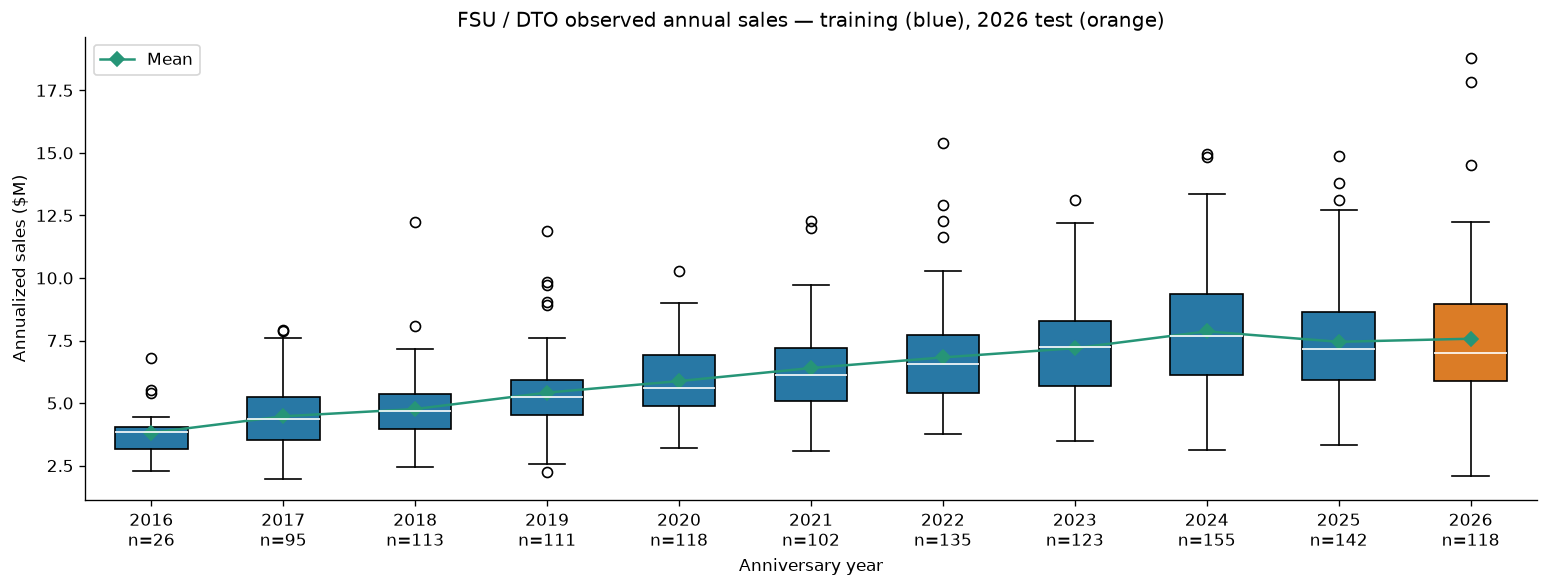

In [20]:
plt.rcParams.update({"figure.facecolor": "white", "axes.spines.top": False, "axes.spines.right": False})
years = sorted(df["year"].unique())
values = [df.loc[df["year"] == year, "annual_sales"].values / 1e6 for year in years]
fig, ax = plt.subplots(figsize=(13, 5))
boxes = ax.boxplot(values, patch_artist=True, widths=0.55, medianprops={"color": "white"})
for box, year in zip(boxes["boxes"], years):
    box.set_facecolor("#db7c26" if year == TEST_YEAR else "#2878a5")
ax.plot(range(1, len(years) + 1), [np.mean(value) for value in values], "D-", color="#269577", label="Mean")
ax.set_xticks(range(1, len(years) + 1), [f"{int(year)}\nn={len(value)}" for year, value in zip(years, values)])
ax.set(title="FSU / DTO observed annual sales — training (blue), 2026 test (orange)", ylabel="Annualized sales ($M)", xlabel="Anniversary year")
ax.legend(); fig.tight_layout()
fig.savefig(OUTPUT_DIR / "sales_by_year.png", dpi=160)
plt.show()

### 19. Compare actual and forecast distributions by SSAM
All SSAM panels use common axis scales. A narrow forecast distribution can
coexist with low average bias, so both residual metrics and distributions matter.

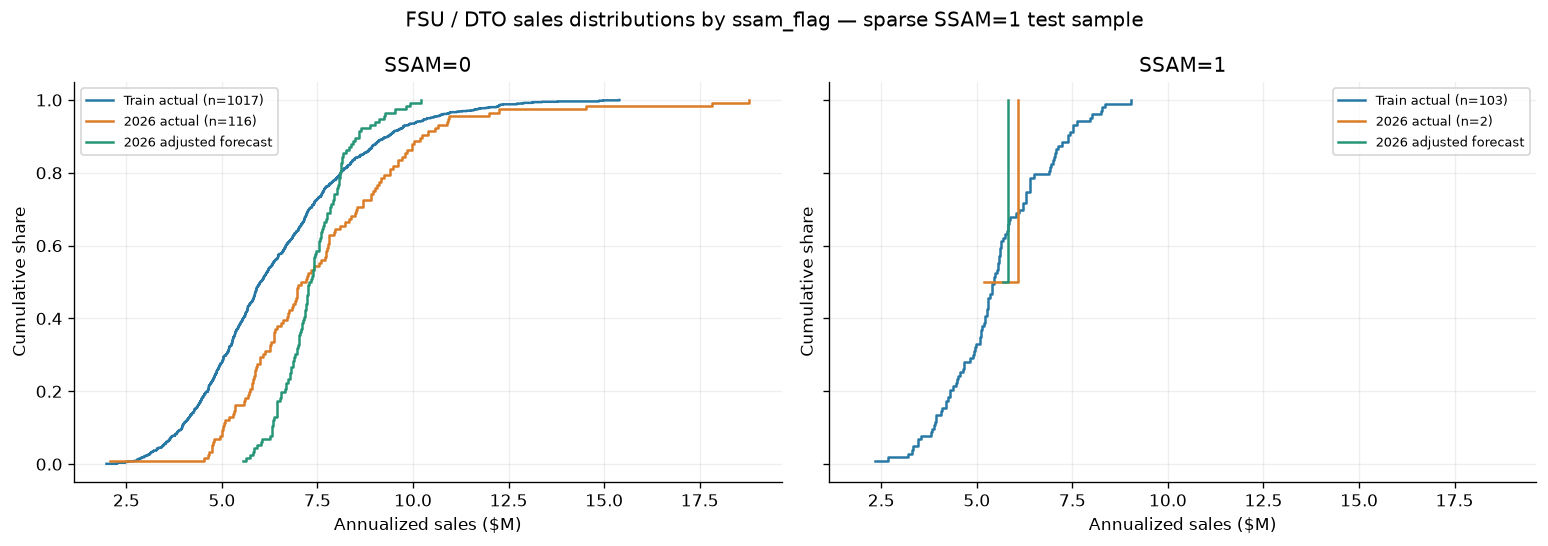

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharex=True, sharey=True)
for ax, flag in zip(axes, [0, 1]):
    train_group = train[train["ssam_flag"] == flag]
    test_group = test_with_predictions[test_with_predictions["ssam_flag"] == flag]
    for label, sales, color in [
        (f"Train actual (n={len(train_group)})", train_group["annual_sales"], "#2878a5"),
        (f"2026 actual (n={len(test_group)})", test_group["annual_sales"], "#db7c26"),
        ("2026 adjusted forecast", test_group["predicted"], "#269577"),
    ]:
        sales = np.sort(np.asarray(sales)) / 1e6
        if len(sales): ax.step(sales, np.arange(1, len(sales) + 1) / len(sales), where="post", label=label, color=color)
    ax.set(title=f"SSAM={flag}", xlabel="Annualized sales ($M)", ylabel="Cumulative share")
    ax.legend(fontsize=8); ax.grid(alpha=0.2)
fig.suptitle("FSU / DTO sales distributions by ssam_flag — sparse SSAM=1 test sample")
fig.tight_layout(); fig.savefig(OUTPUT_DIR / "sales_by_ssam.png", dpi=160)
plt.show()

### 20. Inspect residual offsets by year and forecast level
The 2026 scatter uses actual outcomes for diagnostics only; no correction is
fit to these points. Historical prediction statistics are saved separately.

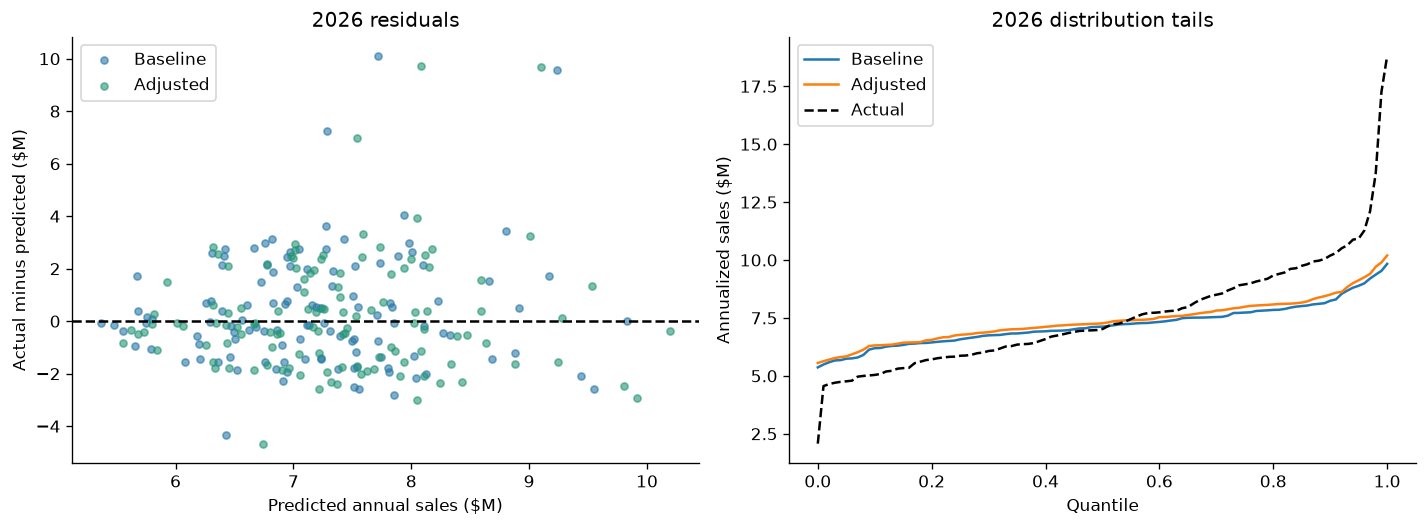

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name, prediction, color in [("Baseline", baseline_prediction, "#2878a5"), ("Adjusted", adjusted_prediction, "#269577")]:
    axes[0].scatter(prediction / 1e6, (test["annual_sales"].values - prediction) / 1e6, label=name, color=color, alpha=0.6, s=18)
axes[0].axhline(0, color="black", linestyle="--")
axes[0].set(xlabel="Predicted annual sales ($M)", ylabel="Actual minus predicted ($M)", title="2026 residuals"); axes[0].legend()
for name, prediction in [("Baseline", baseline_prediction), ("Adjusted", adjusted_prediction)]:
    axes[1].plot(np.linspace(0, 1, 101), np.quantile(prediction / 1e6, np.linspace(0, 1, 101)), label=name)
axes[1].plot(np.linspace(0, 1, 101), np.quantile(test["annual_sales"] / 1e6, np.linspace(0, 1, 101)), "k--", label="Actual")
axes[1].set(xlabel="Quantile", ylabel="Annualized sales ($M)", title="2026 distribution tails"); axes[1].legend()
fig.tight_layout(); fig.savefig(OUTPUT_DIR / "residual_diagnostics.png", dpi=160)
plt.show()

### 21. Refit for inference and export results
Only after evaluation, include mature 2026 labels in production fitting.
MALL receives no forecasts. Older locations without labels and immature/future
locations are identified separately. Exports are in annual dollars.

In [23]:
production_models = {name: train_sales_forecast_model(df, name) for name in selected_weights}
production_fitted = sum(predict_annual_sales(production_models[name], df, name) * weight for name, weight in selected_weights.items())
production_offset = float(np.mean(df["annual_sales"].values - production_fitted))
future["forecast_year"] = future["year"].clip(lower=TEST_YEAR).fillna(TEST_YEAR).astype(int)
future["raw_prediction"] = sum(predict_annual_sales(production_models[name], future, name) * weight for name, weight in selected_weights.items())
future["predicted"] = np.nan
for year, group in future.groupby("forecast_year"):
    prediction = apply_residual_correction(selected_method, selected_correction, group, group["raw_prediction"].values, selected_strength, production_offset)
    future.loc[group.index, "predicted"] = apply_mean_ceiling(prediction, df, year, selected_growth)
future["reason"] = np.where(future["open_date"] >= AS_OF_DATE - pd.DateOffset(years=1), "immature_or_future", "missing_or_ineligible_target")
export_columns = ["location_num", "location_name", "location_type", "open_date", "anniversary", "forecast_year", "subtype", "ssam_flag", "region", "raw_prediction", "predicted", "reason"]
future[export_columns].to_csv(OUTPUT_DIR / "inference_forecasts.csv", index=False)
future.loc[future["location_type"] == "pipeline", export_columns].to_csv(OUTPUT_DIR / "pipeline_forecasts.csv", index=False)
assert not future["subtype"].eq("MALL").any()
assert np.isfinite(future["predicted"]).all() and future["predicted"].gt(0).all()
assert set(future["location_num"]).isdisjoint(df["location_num"])
display(future[export_columns].head())

,location_num,location_name,location_type,open_date,anniversary,forecast_year,subtype,ssam_flag,region,raw_prediction,predicted,reason
0,06980,Nestles Rd. & Los Coches Rd. FSU,pipeline,2029-06-07,2030-06-07,2030,FSU,0,__MISSING__,7.685817e+06,7.863268e+06,immature_or_future
1,06989,Ogden Rd. & Hwy 550 FSU,pipeline,2029-06-07,2030-06-07,2030,FSU,0,__MISSING__,7.052416e+06,7.233950e+06,immature_or_future
2,06988,Ponca City FSU,pipeline,2028-08-03,2029-08-03,2029,FSU,0,__MISSING__,6.376681e+06,6.605158e+06,immature_or_future
3,06990,Mineral Wells FSU,pipeline,2028-08-03,2029-08-03,2029,FSU,0,__MISSING__,5.789933e+06,6.018411e+06,immature_or_future
4,06987,Fishermans Wharf,pipeline,2029-08-03,2030-08-03,2030,FSU,0,__MISSING__,8.098133e+06,8.272925e+06,immature_or_future


### 22. Save the model, diagnostics and run configuration
Preserve feature order, transformations, weights, correction and reference data.
No MLflow registration or Redshift write is performed by this local notebook.
Those integrations can use the same final artifacts after review in Databricks.

In [24]:
with open(OUTPUT_DIR / "model_bundle.pkl", "wb") as file:
    pickle.dump({"models": production_models, "selection": selection, "correction": selected_correction,
                 "training_offset": production_offset, "reference": df[["year", "annual_sales"]],
                 "categorical_features_indices": categorical_features_indices}, file)
distribution_statistics = df.groupby(["year", "subtype", "ssam_flag"])["annual_sales"].agg(["count", "mean", "median", "min", "max"])
distribution_statistics.to_csv(OUTPUT_DIR / "distribution_statistics.csv")
summary = {"selection": selection, "test_metrics": test_metrics.to_dict(orient="records"),
           "train_n": len(train), "test_n": len(test), "eligible_n": len(df), "inference_n": len(future),
           "pipeline_n": int(future["location_type"].eq("pipeline").sum()), "excluded_mall_n": excluded_mall_count,
           "bootstrap_WAPE_difference_95": confidence_interval.tolist(), "input_sha256": input_hash,
           "calibration_candidates": len(ranking), "mean_training_offset": training_mean_offset}
(OUTPUT_DIR / "summary.json").write_text(json.dumps(summary, indent=2))
print("Completed. Outputs saved to:", OUTPUT_DIR.resolve(), flush=True)

Completed. Outputs saved to: C:\Users\SuBae\OneDrive - Green Cabbage\Documents\sales\annual_no_mall_results


### Interpretation and limitations
- Use the no-MALL baseline for an apples-to-apples comparison. Removing MALL
  changes the population and is not itself proof that the forecasting model improved.
- WAPE and mean bias answer different questions. An offset can reduce mean bias
  while increasing individual-store absolute errors.
- Neighbor-sales, growth, demographics and traffic are single-snapshot features;
  their point-in-time availability and exclusion of the target store need verification.
- All figures assume avg_monthly_sales is the relevant annual-average monthly
  measure. The CSV cannot establish that measurement window.
- Training residuals are optimistic; OOF residuals and later-year validation
  provide a better basis for deciding whether a correction transfers.
- The 2026 cohort is partial and has already been inspected during this project.
  Validate any deployment decision on newly mature stores.